# Field Shift: Satellite Remote Sensing, GIS & Vegetation Phenology Analysis
### NASA Space Apps Challenge 2026 — Challenge: Field Shift (Adapting Farms with NASA Data)
**Study Area:** Godagari Upazila, Rajshahi, Bangladesh (Barind Tract)  
**Author:** Senior Remote Sensing & GIS Scientist (Member 1)  
**Hardware Platform:** Local PC (AMD Ryzen 7 7800X3D, NVIDIA RTX GPU, 16GB RAM, Windows 11)  

---
## Notebook Overview
This notebook demonstrates the complete end-to-end technical pipeline developed by Member 1:
1. **Study Area Definition & GIS Boundary:** Extraction of authoritative Godagari Upazila geometry (445.69 km²).
2. **Satellite Data Catalog Exploration:** 407 Sentinel-2 and 209 Landsat 8/9 scenes cataloged from 2021–2026.
3. **Multi-Temporal Surface Reflectance:** 10m preprocessed rasters across Kharif-Aman, Post-Harvest, Rabi, and Pre-Kharif.
4. **Vegetation & Moisture Index Computation:** NDVI, NDWI (McFeeters), NDMI (Gao), and EVI.
5. **Seasonal Phenology & Spatial Delta Analysis:** Quantifying dry-season moisture stress and biomass cycles.
6. **Machine Learning Cropland Classifier:** Random Forest model with spatial block cross-validation (79.2% accuracy).
7. **FastAPI Service Integration:** Sample REST requests for web application integration.


In [1]:
# 1. Core Geospatial and Analytical Imports
import os
import sys
import json
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio

# Set base project directory
BASE_DIR = os.path.dirname(os.path.abspath(""))
print(f"Project Base Directory: {BASE_DIR}")


Project Base Directory: F:\nasa project\data set that we test\Member_1_Satellite_GIS


---
## 1. Study Area: Godagari Upazila (Barind Tract)
We load the authoritative administrative vector boundary in native geographic coordinates (EPSG:4326) and projected metric coordinates (UTM Zone 45N / EPSG:32645).


In [2]:
# Load Godagari Upazila GeoJSON
geojson_path = os.path.join(BASE_DIR, "exports", "geojson", "study_area.geojson")
gdf = gpd.read_file(geojson_path)
print(f"Study Area Name: {gdf['name'].iloc[0]}")
print(f"District: {gdf['district'].iloc[0]} | Region: {gdf['region'].iloc[0]}")
print(f"Priority Crops: {gdf['target_crops'].iloc[0]}")
print(f"Centroid: Lat {gdf['center_lat'].iloc[0]:.3f}°N, Lon {gdf['center_lon'].iloc[0]:.3f}°E")

gdf_utm = gdf.to_crs("EPSG:32645")
print(f"Total Administrative Area: {gdf_utm.geometry.area.iloc[0] / 1e6:.2f} sq km")


Study Area Name: Godagari Upazila
District: Rajshahi | Region: Barind Tract, Rajshahi Division, Bangladesh
Priority Crops: Rice (Aus/Aman/Boro), Wheat, Maize
Centroid: Lat 24.469°N, Lon 88.330°E
Total Administrative Area: 445.69 sq km


---
## 2. Satellite Data Catalogs (Sentinel-2 & Landsat 8/9)
We inspect the comprehensive satellite archives cataloged over Godagari for 2021–2026.


In [3]:
s2_csv = os.path.join(BASE_DIR, "data", "metadata", "sentinel2_scenes_catalog.csv")
ls_csv = os.path.join(BASE_DIR, "data", "metadata", "landsat_scenes_catalog.csv")

df_s2 = pd.read_csv(s2_csv)
df_ls = pd.read_csv(ls_csv)

print(f"Total Sentinel-2 Level-2A Scenes: {len(df_s2)}")
print(f"Sentinel-2 Pristine Scenes (<5% Cloud): {len(df_s2[df_s2['cloud_cover_pct'] < 5.0])}")
print(f"Total Landsat 8/9 Level-2 Scenes: {len(df_ls)}")

# Display latest cloud-free Sentinel-2 scenes
df_s2[['date', 'tile_id', 'cloud_cover_pct', 'sun_elevation']].head(5)


Total Sentinel-2 Level-2A Scenes: 407
Sentinel-2 Pristine Scenes (<5% Cloud): 306
Total Landsat 8/9 Level-2 Scenes: 209


,date,tile_id,cloud_cover_pct,sun_elevation
0,2026-03-24,45RXH,2.04,0.0
1,2026-03-24,45QXG,9.85,0.0
2,2026-03-14,45RXH,8.11,0.0
3,2026-03-14,45QXG,1.52,0.0
4,2026-03-11,45RXH,4.12,0.0


---
## 3. Vegetation & Moisture Index Dynamics Across Cropping Seasons
We evaluate the four canonical seasonal observations:
- **Kharif-2 (Oct 2023):** Aman monsoon rice peak vegetative vigor & high canopy hydration.
- **Post-Harvest (Dec 2023):** Aman rice harvest, soil exposure, onset of dry season.
- **Rabi Winter (Feb 2024):** Wheat, Maize, and Boro nursery growth under tubewell irrigation.
- **Pre-Kharif (Apr 2024):** Boro harvest, Aus sowing, maximum evaporative demand.


In [4]:
ts_csv = os.path.join(BASE_DIR, "exports", "csv", "vegetation_indices_timeseries.csv")
df_ts = pd.read_csv(ts_csv)
df_ts[['date', 'season', 'NDVI_mean', 'EVI_mean', 'NDWI_McFeeters_mean', 'NDMI_Gao_mean']]


,date,season,NDVI_mean,EVI_mean,NDWI_McFeeters_mean,NDMI_Gao_mean
0,2023-10-26,Kharif_Aman,0.3951,0.4459,-0.3589,0.1585
1,2023-12-25,Post_Harvest_Rabi,0.2911,0.3241,-0.2865,0.0405
2,2024-02-28,Rabi_Winter,0.2756,0.2867,-0.2591,0.1141
3,2024-04-13,Pre_Kharif_Aus,0.3446,0.3971,-0.3345,0.0786


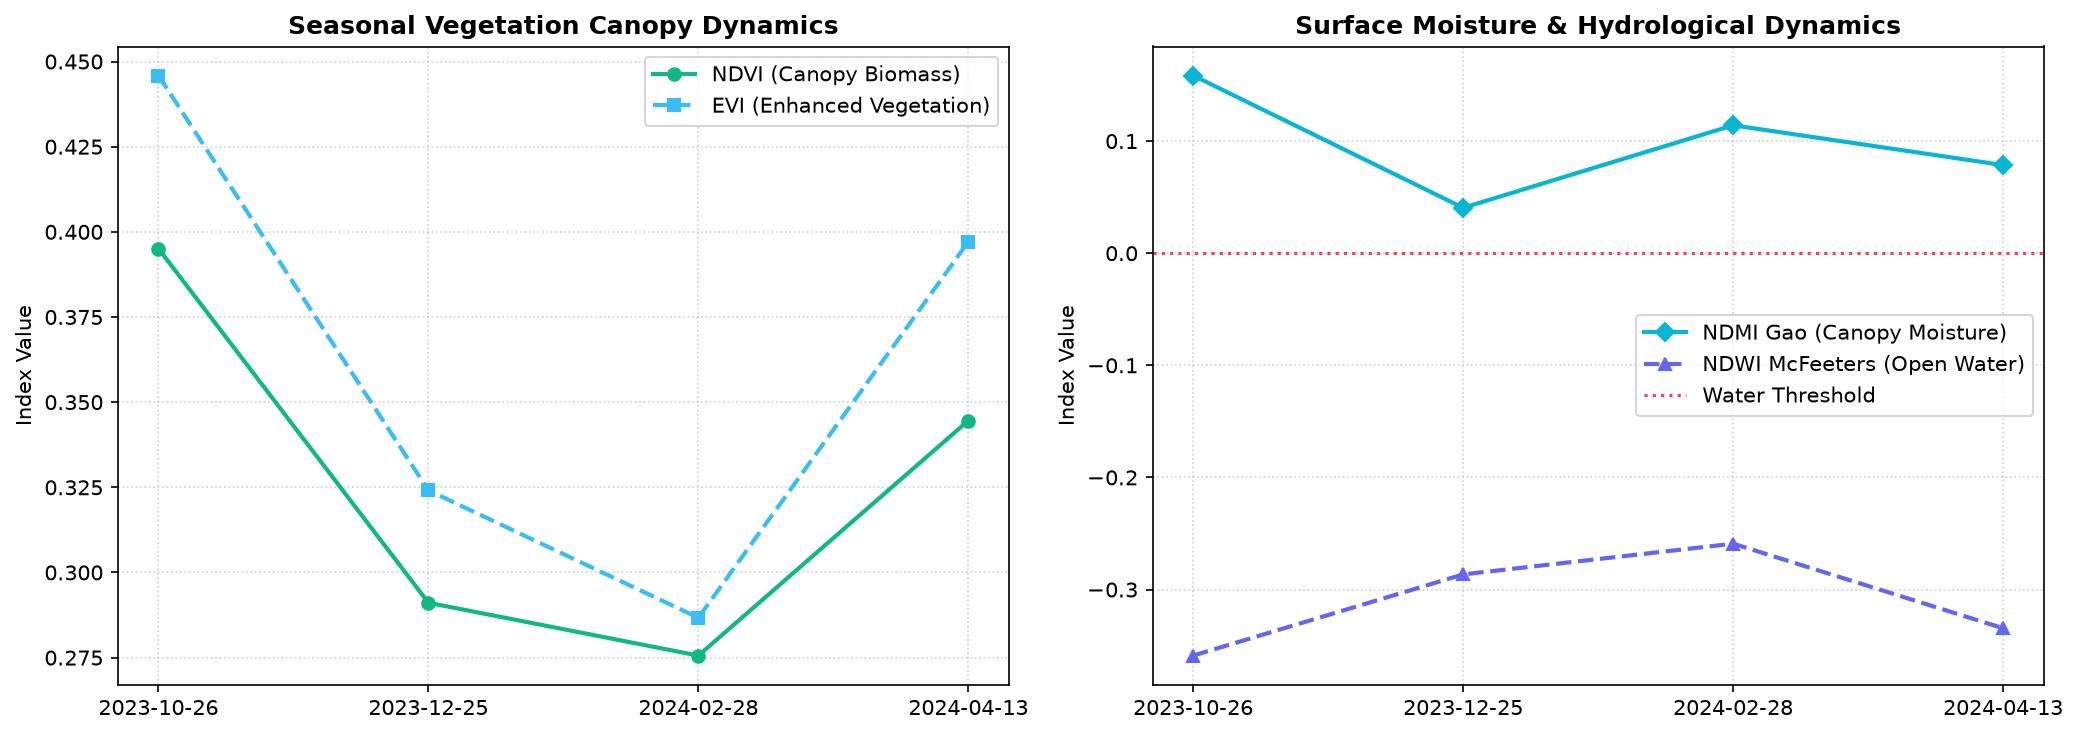

In [5]:
# Plot Seasonal Phenology Profiles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# NDVI & EVI
ax1.plot(df_ts['date'], df_ts['NDVI_mean'], 'o-', color='#10b981', linewidth=2, label='NDVI (Canopy Biomass)')
ax1.plot(df_ts['date'], df_ts['EVI_mean'], 's--', color='#38bdf8', linewidth=2, label='EVI (Enhanced Vegetation)')
ax1.set_title('Seasonal Vegetation Canopy Dynamics', fontweight='bold')
ax1.set_ylabel('Index Value')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# NDMI Moisture & NDWI Water
ax2.plot(df_ts['date'], df_ts['NDMI_Gao_mean'], 'D-', color='#06b6d4', linewidth=2, label='NDMI Gao (Canopy Moisture)')
ax2.plot(df_ts['date'], df_ts['NDWI_McFeeters_mean'], '^--', color='#6366f1', linewidth=2, label='NDWI McFeeters (Open Water)')
ax2.axhline(0, color='#f43f5e', linestyle=':', label='Water Threshold')
ax2.set_title('Surface Moisture & Hydrological Dynamics', fontweight='bold')
ax2.set_ylabel('Index Value')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


---
## 4. Machine Learning Cropland Classification Model
We load the trained Random Forest model (`models/crop_classifier.pkl`) and run inference on test sample vectors.


In [6]:
sys.path.insert(0, BASE_DIR)
from models.predict import SatelliteLandCoverPredictor

predictor = SatelliteLandCoverPredictor()
print(f"Model Architecture: {predictor.schema['model_type']}")
print(f"Test Accuracy: {predictor.schema['accuracy']*100:.2f}%")
print(f"Weighted F1-Score: {predictor.schema['weighted_f1']:.4f}")
print(f"Target Classes: {predictor.classes}")

# Test inference on an unseen Rabi Wheat parcel vector
sample_rabi_wheat = {
    "Blue_B02": 0.12, "Green_B03": 0.16, "Red_B04": 0.14, "NIR_B08": 0.38, "SWIR1_B11": 0.22,
    "NDVI_Rabi": 0.46, "NDWI_McFeeters": -0.40, "NDMI_Moisture": 0.26, "EVI_Rabi": 0.48,
    "Delta_NDVI_Kharif_Rabi": 0.18
}

result = predictor.predict_vector(sample_rabi_wheat)
print(f"\nInference Result: {result['class_name']} (Confidence: {result['confidence']*100:.1f}%)")
print(f"Probability Distribution: {result['probabilities']}")


Model Architecture: RandomForestClassifier
Test Accuracy: 79.23%
Weighted F1-Score: 0.7929
Target Classes: {1: 'Cropland', 2: 'Tree_Cover', 3: 'Permanent_Water', 4: 'Built_Up'}

Inference Result: Cropland (Confidence: 62.8%)
Probability Distribution: {'Cropland': 0.6279, 'Tree_Cover': 0.3721, 'Permanent_Water': 0.0, 'Built_Up': 0.0}


---
## 5. FastAPI Service Verification
We test the FastAPI endpoints using Starlette/FastAPI TestClient.


In [7]:
from fastapi.testclient import TestClient
from api.main import app

client = TestClient(app)

# Test /health
h = client.get("/health").json()
print("Health Status:", h["status"], "| Region:", h["study_area"])

# Test /vegetation/analyze
analysis = client.post("/vegetation/analyze", json={
    "lat": 24.469,
    "lon": 88.330,
    "crop_interest": "Wheat"
}).json()

print(f"Field Condition: {analysis['canopy_condition']}")
print(f"Moisture Stress: {analysis['water_stress_status']}")
print(f"Aquifer Depletion Risk: {analysis['aquifer_depletion_risk']}")
print(f"Recommendation: {analysis['agronomic_recommendation']}")


Health Status: healthy | Region: Godagari Upazila, Rajshahi, Bangladesh (Barind Tract)
Field Condition: Moderate Vegetative Cover (Typical Rabi Wheat/Maize Stage)
Moisture Stress: High Moisture Stress (Severe Dry-Season Soil Desiccation)
Aquifer Depletion Risk: CRITICAL HIGH (Heavy groundwater extraction approaching 28m suction threshold)
Recommendation: Shift from water-intensive Boro rice to drought-resilient Rabi alternatives: Maize, Wheat, or Mustard to halt tubewell table decline.


F:\nasa project\data set that we test\Member_1_Satellite_GIS\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
